# Heart Disease Prediction with a Support Vector Classifier

**Goal.** Predict whether a patient has heart disease from four simple inputs: **age**, **sex**, **chest pain type (cp)** and **maximum heart rate achieved (thalach)**.

**Data.** UCI Cleveland Heart Disease dataset: 303 patients, 13 clinical attributes and one diagnosis column.

**Model.** A scikit-learn `Pipeline` that standardizes the inputs and then classifies them with an RBF-kernel Support Vector Classifier (SVC).

### Machine learning pipeline followed in this notebook

| Stage | What happens | Section |
|---|---|---|
| 1. Setup | Import libraries | Step 1 |
| 2. Data loading | Read the raw file and name the columns | Step 2 |
| 3. Data understanding (EDA) | Check structure, missing values, distributions, correlations | Step 3 |
| 4. Preprocessing: target | Convert the 5-class diagnosis into a binary label | Step 4 |
| 5. Feature selection | Choose the four model inputs | Step 5 |
| 6. Data splitting | Create training and testing sets | Step 6 |
| 7. Model training | Fit the scaler + SVC pipeline | Step 7 |
| 8. Evaluation | Accuracy, cross-validation, precision/recall, confusion matrix | Step 8 |
| 9. Model persistence | Save and reload the model for deployment | Step 9 |

Every code cell is preceded by a note stating the pipeline stage and the reason for the approach used.

> This project is for learning purposes only and is not a medical diagnostic tool.

## Step 1: Setup

### 1.1 Import libraries

**Pipeline stage:** Setup

**What this cell does:** Loads every library used later in the notebook.

**Why this approach:** All imports are grouped in one cell so the dependencies are visible at a glance and the notebook fails early if a package is missing. Each import was previously repeated in later cells; they are consolidated here without changing any behavior.

In [2]:
# ============================================================
# Libraries used throughout this notebook
# ============================================================

# --- Data handling ---------------------------------------------------------
# pandas manages tabular data (DataFrames), file reading and group summaries.
import pandas as pd

# numpy supports numerical operations on arrays.
import numpy as np

# --- Visualization ---------------------------------------------------------
# matplotlib and seaborn help us visualize data (histograms, heatmaps, plots).
import matplotlib.pyplot as plt
import seaborn as sns

# --- Data splitting and validation -----------------------------------------
# train_test_split divides data into training and testing sets.
# cross_val_score measures performance across several train/validation folds.
from sklearn.model_selection import train_test_split, cross_val_score

# --- Preprocessing ---------------------------------------------------------
# StandardScaler standardizes numeric features (mean 0, standard deviation 1).
from sklearn.preprocessing import StandardScaler

# --- Model -----------------------------------------------------------------
# SVC is the Support Vector Classifier.
from sklearn.svm import SVC

# Pipeline joins preprocessing and model training into one object.
from sklearn.pipeline import Pipeline

# --- Evaluation metrics ----------------------------------------------------
# These metrics help us evaluate the model.
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# --- Persistence -----------------------------------------------------------
# pickle saves and loads trained Python objects.
import pickle

print("All required libraries imported successfully.")

All required libraries imported successfully.


## Step 2: Data Loading

### 2.1 Read the Cleveland dataset

**Pipeline stage:** Data loading

**What this cell does:** Reads the raw file into a DataFrame, names the 14 columns and converts the `?` placeholders into proper missing values.

**Why this approach:** The raw file has no header row and uses `?` for missing entries. Supplying `header=None`, explicit `names` and `na_values="?"` makes pandas read the file correctly, so numeric columns stay numeric and missing data can be detected later.

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | 1 = male, 0 = female |
| `cp` | Chest pain type (1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic) |
| `trestbps` | Resting blood pressure |
| `chol` | Serum cholesterol |
| `fbs` | Fasting blood sugar above 120 mg/dl (1 = yes) |
| `restecg` | Resting electrocardiogram result |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = yes) |
| `oldpeak` | ST depression induced by exercise |
| `slope` | Slope of the peak exercise ST segment |
| `ca` | Number of major vessels colored by fluoroscopy |
| `thal` | Thallium stress test result |
| `target` | Diagnosis: 0 = no disease, 1 to 4 = disease of increasing severity |

In [4]:
# The original dataset does not contain column names in its first row.
# Therefore, we create a list of meaningful names for all 14 columns.
# The order of these names must match the order of columns in the file.
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]


# Load the dataset into a pandas DataFrame named 'df'.
# A DataFrame is a table containing rows and columns, similar to Excel.
# NOTE: the path below is the Google Colab upload location. Change it if you
# run the notebook somewhere else.
df = pd.read_csv(
    "/content/processed.cleveland.data",

    # header=None tells pandas that the file has no header row.
    # Without this, pandas would treat the first patient's record
    # as column names, which would be incorrect.
    header=None,

    # Assign the column names we defined above to the 14 columns.
    names=columns,

    # In this dataset, '?' represents a missing value.
    # Convert these question marks into missing-value markers (NaN)
    # so we can identify and handle missing data later.
    na_values="?"
)


# Print the shape of the DataFrame.
# df.shape returns a tuple: (number of rows, number of columns).
# We expect (303, 14) for this particular Cleveland dataset.
print("Dataset shape:", df.shape)


# Display the first five rows.
# This lets us check whether the data loaded correctly and inspect
# the values and column names before doing any machine learning.
print(df.head())

# Visual separator between the outputs.
print("============================================================")

Dataset shape: (303, 14)
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  


## Step 3: Exploratory Data Analysis (EDA)

Before modeling, we check the size, data types, missing values, duplicates, value ranges, distributions and relationships in the data.

### 3.1 Confirm the dataset structure

**Pipeline stage:** Data understanding

**What this cell does:** Prints the shape, the number of columns and the column names.

**Why this approach:** A quick structural check immediately after loading confirms that the file was parsed into 303 rows and 14 columns as expected, before any deeper analysis.

In [ ]:
# Shape is (number of rows, number of columns).
print("Shape:", df.shape)

# Count the columns and list their names to confirm they match
# the names assigned while loading the data.
print("Number of columns:", len(df.columns))
print("Column names:", df.columns.tolist())

Shape: (303, 14)
Number of columns: 14
Column names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


### 3.2 Data quality report

**Pipeline stage:** Data understanding (data quality)

**What this cell does:** Reports column names, row count, data types, missing values per column and duplicate rows.

**Why this approach:** Missing values and duplicates must be known before modeling because most algorithms (including SVC) cannot accept missing values and duplicates can distort evaluation. The report shows that only `ca` (4 missing) and `thal` (2 missing) have gaps, and there are no duplicate rows.

In [5]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
3. Checking data types, missing values and duplicate rows.
"""

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(df.columns)

# Print a header for instance count
# count() counts non-missing values; 'age' has no gaps, so it equals the row count.
print("\n\nNumber of Instances in Sample Data:", df["age"].count())
print("========================================\n")

# info() summarizes each column's data type and non-null count in one view.
print("\nDataset information:")
df.info()
print("========================================\n")


# dtypes lists the data type of every column (float64 / int64 here).
print("\nDataset types:")
print(df.dtypes)
print("========================================\n")


# Count missing values in each column.
# isnull() marks missing entries as True; sum() counts them per column.
print("\nMissing values per column:")
print(df.isnull().sum())

# Total missing values in the dataset
print("\nTotal Missing values:")
print(df.isnull().sum().sum())

print("========================================\n")

# duplicated() flags rows that are exact copies of an earlier row.
print("\nDuplicate values:")
print(df.duplicated().sum())



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


Number of Instances in Sample Data: 303


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(1

### 3.3 Numerical summaries and category counts

**Pipeline stage:** Data understanding (descriptive statistics)

**What this cell does:** Prints summary statistics for the five continuous columns and frequency tables for the coded (categorical) columns. It also defines `numerical_cols` and `categorical_cols`, which later cells reuse.

**Why this approach:** Continuous variables are best described with count, mean, spread and quartiles, whereas coded variables (such as `sex` or `cp`) are best described by how often each code occurs. Splitting the columns into these two groups lets each get the summary that makes sense for it. `dropna=False` keeps missing values visible in the counts.

In [6]:
# --- Continuous (numerical) columns -----------------------------------------
# These measure quantities on a scale, so mean/std/quartiles are meaningful.
numerical_cols = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Summary statistics: count, mean, std, min, quartiles and max.
print(df[numerical_cols].describe())

# --- Coded (categorical) columns --------------------------------------------
# These store category codes (for example sex: 0/1), so we count occurrences.
categorical_cols = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal",
    "target"
]


# Frequency of each code. dropna=False keeps missing values visible,
# and sort_index() lists the codes in ascending order.
for col in categorical_cols:
    print(f"\n{col} distribution:")
    print(df[col].value_counts(dropna=False).sort_index())


# List the distinct codes found in each categorical column
# so we can compare them with the dataset documentation.
for col in categorical_cols:
    print(col, sorted(df[col].dropna().unique()))

              age    trestbps        chol     thalach     oldpeak
count  303.000000  303.000000  303.000000  303.000000  303.000000
mean    54.438944  131.689769  246.693069  149.607261    1.039604
std      9.038662   17.599748   51.776918   22.875003    1.161075
min     29.000000   94.000000  126.000000   71.000000    0.000000
25%     48.000000  120.000000  211.000000  133.500000    0.000000
50%     56.000000  130.000000  241.000000  153.000000    0.800000
75%     61.000000  140.000000  275.000000  166.000000    1.600000
max     77.000000  200.000000  564.000000  202.000000    6.200000

sex distribution:
sex
0.0     97
1.0    206
Name: count, dtype: int64

cp distribution:
cp
1.0     23
2.0     50
3.0     86
4.0    144
Name: count, dtype: int64

fbs distribution:
fbs
0.0    258
1.0     45
Name: count, dtype: int64

restecg distribution:
restecg
0.0    151
1.0      4
2.0    148
Name: count, dtype: int64

exang distribution:
exang
0.0    204
1.0     99
Name: count, dtype: int64

slope d

### 3.4 Distributions of the numerical features

**Pipeline stage:** Data understanding (visual analysis)

**What this cell does:** Draws a histogram for each continuous column.

**Why this approach:** Histograms show the shape of each variable (skewness, spread, unusual values) at a glance, which numbers alone cannot. This also reveals that the features are on very different scales, which motivates the scaling step used in training.

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'trestbps'}>],
       [<Axes: title={'center': 'chol'}>,
        <Axes: title={'center': 'thalach'}>],
       [<Axes: title={'center': 'oldpeak'}>, <Axes: >]], dtype=object)

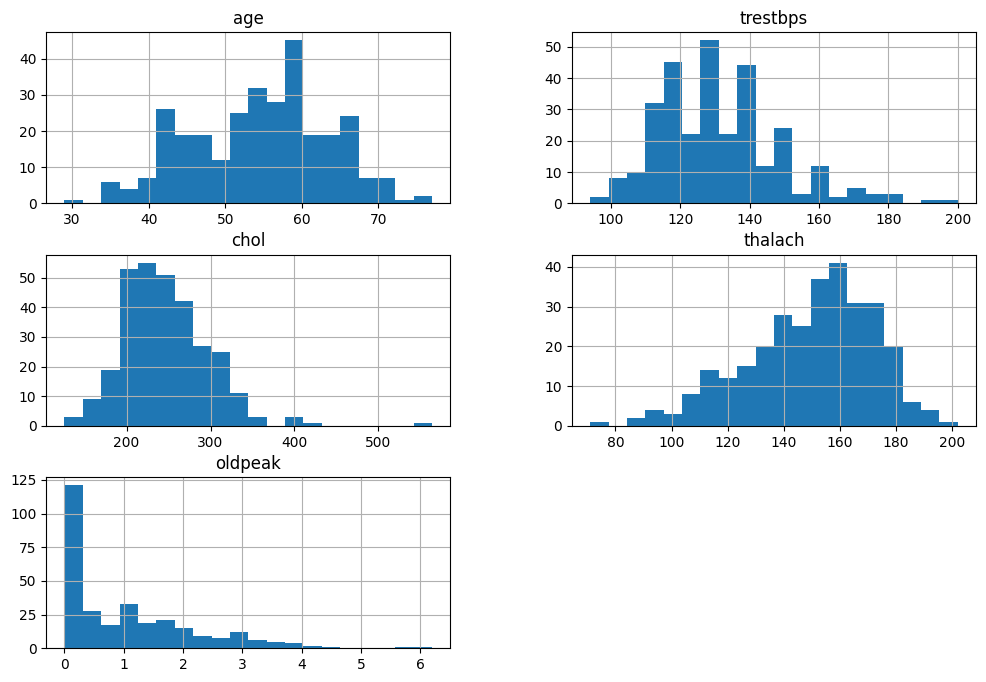

In [7]:
# Draw one histogram per numerical column.
# bins=20 splits each feature's range into 20 intervals;
# figsize sets the overall figure size (width, height in inches).
df[numerical_cols].hist(figsize=(12, 8), bins=20)

### 3.5 Correlation between numerical features

**Pipeline stage:** Data understanding (relationships)

**What this cell does:** Plots a heatmap of pairwise correlations between the continuous columns.

**Why this approach:** A correlation heatmap quickly shows which variables move together. Strongly correlated inputs would carry overlapping information, so this is a standard check before choosing features.

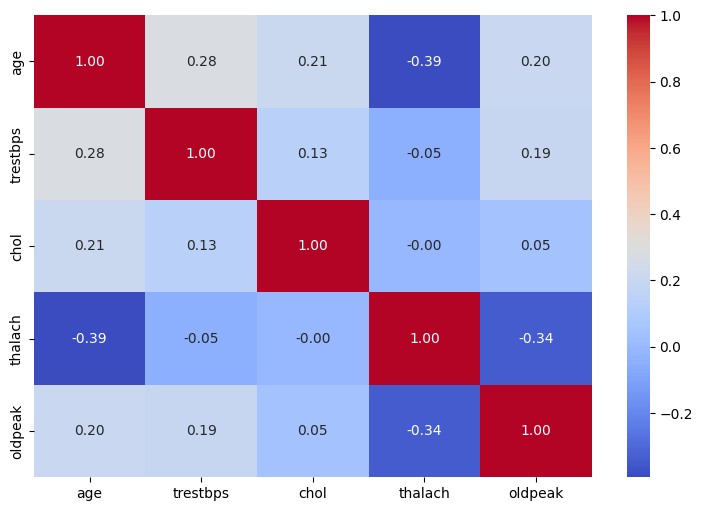

In [8]:
# Pairwise Pearson correlations between the numerical columns.
# Values range from -1 (opposite) through 0 (unrelated) to +1 (move together).
corr = df[numerical_cols].corr()

# Draw the correlation matrix as a heatmap.
# annot=True prints the value in each cell; fmt=".2f" shows two decimals;
# the "coolwarm" palette uses red for positive and blue for negative values.
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

### 3.7 Full-column summary and original target distribution

**Pipeline stage:** Data understanding (scale and class balance)

**What this cell does:** Summarizes every column, counts distinct values per column and shows the original five-class target as counts and percentages.

**Why this approach:** The transposed summary compares the scale of all columns side by side, the unique-value counts help identify coded versus continuous features, and the target percentages reveal class balance. The original target is heavily weighted toward class 0 (about 54%), with classes 1 to 4 making up the rest in smaller groups, which leads to the decision in Step 4.

> Note: the saved output of this cell also lists a `disease` row because the cell was originally run after Step 4. On a fresh top-to-bottom run that row will not appear, which does not affect any result.

In [10]:
# PART A: Inspect the numerical summaries of all columns.
# The summary includes count, mean, standard deviation, minimum,
# quartiles, and maximum. It helps us spot unusual values and scales.
# The transpose (.T) puts each feature on its own row for easier reading.
print(df.describe().T)

# PART B: Count the distinct values in every column.
# A low number of unique values may indicate an encoded category
# or a binary feature, although we must confirm this using documentation.
print("\nNumber of unique values in each column:")
print(df.nunique())

# PART C: Display the original target classes and their counts.
# value_counts() tells us how many records belong to each class.
# dropna=False also makes missing target values visible, if any exist.
print("\nOriginal target distribution:")
print(df["target"].value_counts(dropna=False).sort_index())

# PART D: Display the target proportions as percentages.
# normalize=True converts counts into proportions; multiplying by 100
# expresses them as percentages, making class balance easier to assess.
print("\nOriginal target percentages:")
print((df["target"].value_counts(normalize=True, dropna=False)
       .sort_index() * 100).round(2))

          count        mean        std    min    25%    50%    75%    max
age       303.0   54.438944   9.038662   29.0   48.0   56.0   61.0   77.0
sex       303.0    0.679868   0.467299    0.0    0.0    1.0    1.0    1.0
cp        303.0    3.158416   0.960126    1.0    3.0    3.0    4.0    4.0
trestbps  303.0  131.689769  17.599748   94.0  120.0  130.0  140.0  200.0
chol      303.0  246.693069  51.776918  126.0  211.0  241.0  275.0  564.0
fbs       303.0    0.148515   0.356198    0.0    0.0    0.0    0.0    1.0
restecg   303.0    0.990099   0.994971    0.0    0.0    1.0    2.0    2.0
thalach   303.0  149.607261  22.875003   71.0  133.5  153.0  166.0  202.0
exang     303.0    0.326733   0.469794    0.0    0.0    0.0    1.0    1.0
oldpeak   303.0    1.039604   1.161075    0.0    0.0    0.8    1.6    6.2
slope     303.0    1.600660   0.616226    1.0    1.0    2.0    2.0    3.0
ca        299.0    0.672241   0.937438    0.0    0.0    0.0    1.0    3.0
thal      301.0    4.734219   1.939706

## Step 4: Preprocessing the Target

### 4.1 Convert the diagnosis into a binary label

**Pipeline stage:** Preprocessing (target engineering)

**What this cell does:** Creates a new `disease` column (0 = no disease, 1 = disease present), checks the resulting class balance and measures how each column correlates with it.

**Why this approach:**
- **Binary instead of five classes:** classes 1 to 4 each contain few records (13 to 55), which is too little data per class for a reliable multi-class model. Merging them into a single "disease present" class gives a simpler question (is disease present or not?) and more examples per class.
- **A new column rather than overwriting:** the original `target` column is preserved, so no information is lost.
- **Balance check:** the merged classes are roughly balanced (about 54% / 46%), so accuracy remains a meaningful metric.
- **Correlations:** an initial look at which features relate most strongly to the label. This is exploration only, not a final feature-selection method, and correlation does not prove causation.

In [11]:
# STEP 1: Create a binary target in a separate column.
# Original target 0 means no disease.
# Original targets 1, 2, 3, and 4 mean disease is present.
# The new column will contain only:
# 0 = no disease
# 1 = disease present
#
# We preserve the original 'target' column so we can compare results
# and avoid losing the original information.
df["disease"] = (df["target"] > 0).astype(int)

# STEP 2: Count the records in each new class.
# This checks the class balance after combining the original classes.
print("Binary target counts:")
print(df["disease"].value_counts().sort_index())

# STEP 3: Calculate the percentage of each class.
# normalize=True calculates proportions instead of raw counts.
print("\nBinary target percentages:")
print(
    (df["disease"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

# STEP 4: Calculate correlations between numeric columns and the
# binary disease indicator.
# This is an initial exploration, not a final feature-selection method.
# Correlation can help reveal patterns, but it cannot prove causation.
print("\nFeature correlations with binary disease target:")
print(
    df.drop(columns=["target"])
      .corr(numeric_only=True)["disease"]
      .drop("disease")
      .sort_values(key=abs, ascending=False)
)

Binary target counts:
disease
0    164
1    139
Name: count, dtype: int64

Binary target percentages:
disease
0    54.13
1    45.87
Name: proportion, dtype: float64

Feature correlations with binary disease target:
thal        0.525689
ca          0.460442
exang       0.431894
oldpeak     0.424510
thalach    -0.417167
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
Name: disease, dtype: float64


## Step 5: Feature Selection

### 5.1 Define the model inputs (X) and the label (y)

**Pipeline stage:** Feature selection

**What this cell does:** Selects `age`, `sex`, `cp` and `thalach` as the model inputs (`X`), uses `disease` as the label (`y`) and verifies shapes, missing values and class counts.

**Why this approach:**
- **A small, fixed input set:** four inputs keep the final prediction form short and easy for a user to fill in.
- **Clean inputs:** these four columns have no missing values (the only gaps in the dataset are in `ca` and `thal`), so no imputation step is required.
- **Informative inputs:** `cp` and `thalach` are among the stronger correlates of disease in Step 4.1, and `sex` and `age` are basic patient details that are always available.
- **Keeping `X` and `y` separate:** the model learns from `X` and is scored against `y`.

In [12]:
# Select exactly four input features.
# These columns will be used by the model to make predictions.
selected_features = ["age", "sex", "cp", "thalach"]

# Create X, which contains the model's input features.
# The double brackets select multiple columns from the DataFrame.
X = df[selected_features]

# Create y, which contains the correct answers for training.
# 0 means no disease; 1 means disease is present.
y = df["disease"]

# Display the dimensions to verify the selection.
# X should have 303 rows and 4 columns.
# y should have 303 values, one for each row.
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

# Display the first five input records.
# This lets us confirm that only the four selected columns are present.
print(X.head())

# Check whether any selected input feature contains missing values.
# A zero count for every feature means no missing-value handling
# is needed for these four inputs.
print("Missing values in selected features:")
print(X.isnull().sum())

# Check the target class counts one more time.
# This confirms that y contains the two classes we intend to predict.
print("Target class counts:")
print(y.value_counts().sort_index())

Input features shape: (303, 4)
Target shape: (303,)
    age  sex   cp  thalach
0  63.0  1.0  1.0    150.0
1  67.0  1.0  4.0    108.0
2  67.0  1.0  4.0    129.0
3  37.0  1.0  3.0    187.0
4  41.0  0.0  2.0    172.0
Missing values in selected features:
age        0
sex        0
cp         0
thalach    0
dtype: int64
Target class counts:
disease
0    164
1    139
Name: count, dtype: int64


### 5.2 Check that the chosen features relate to the outcome

**Pipeline stage:** Feature selection (validation)

**What this cell does:** Computes the disease rate for each sex category and each chest pain type.

**Why this approach:** Group-wise rates are an easy-to-read sanity check that the categorical inputs carry signal. The output shows a much higher disease rate for sex = 1 (about 55%) than sex = 0 (about 26%), and for chest pain type 4 (about 73%) than for the other types (18% to 30%). Taking the mean of a 0/1 column gives the proportion with disease, and multiplying by 100 converts it to a percentage.

In [13]:
# Calculate the percentage with disease for each sex category.
# Multiplying the mean by 100 converts a proportion to a percentage.
print("Disease rate by sex (%):")
print((df.groupby("sex")["disease"].mean() * 100).round(2))

# Calculate the percentage with disease for each chest pain category.
print("\nDisease rate by cp (%):")
print((df.groupby("cp")["disease"].mean() * 100).round(2))

Disease rate by sex (%):
sex
0.0    25.77
1.0    55.34
Name: disease, dtype: float64

Disease rate by cp (%):
cp
1.0    30.43
2.0    18.00
3.0    20.93
4.0    72.92
Name: disease, dtype: float64


## Step 6: Data Splitting

### 6.1 Create training and testing sets

**Pipeline stage:** Data splitting

**What this cell does:** Divides the data into 80% training (242 records) and 20% testing (61 records).

**Why this approach:**
- **Hold-out test set:** the test records are never used for learning, so the final accuracy estimates how the model performs on unseen patients.
- **`test_size=0.20`:** a common split that leaves enough data to train on while keeping a usable test set; with only 303 records, a much larger test share would starve the model.
- **`random_state=42`:** makes the split repeatable, so results can be reproduced.
- **`stratify=y`:** keeps the disease / no-disease proportions the same in both sets, so neither set is accidentally skewed.

In [14]:
# Use the four selected input features created earlier.
# X contains age, sex, cp, and thalach.
# y contains 0 = no disease and 1 = disease present.
#
# Keep 20% of the records for testing.
# random_state=42 makes the split repeatable.
# stratify=y keeps the class proportions similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Print the sizes to confirm the split worked.
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 242
Testing records: 61


### 6.2 Verify the class balance after the split

**Pipeline stage:** Data splitting (verification)

**What this cell does:** Prints the class counts in the training and testing sets.

**Why this approach:** This confirms that stratification worked. Both sets keep roughly the original 54% / 46% balance (131 / 111 in training, 33 / 28 in testing).

In [15]:
# Class counts in the training set.
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

# Class counts in the testing set; they should mirror the training proportions.
print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Training class distribution:
disease
0    131
1    111
Name: count, dtype: int64

Testing class distribution:
disease
0    33
1    28
Name: count, dtype: int64


## Step 7: Model Training

### 7.1 Build and train the scaler + SVC pipeline

**Pipeline stage:** Preprocessing (scaling) and model training

**What this cell does:** Builds a `Pipeline` with a `StandardScaler` followed by an `SVC`, then trains it on the training data only.

**Why this approach:**
- **`StandardScaler`:** the inputs are on very different scales (`thalach` is around 150, `age` around 54, while `sex` is 0 or 1 and `cp` runs 1 to 4). SVC with an RBF kernel is distance-based, so unscaled large-valued features would dominate. Standardizing puts them on equal footing.
- **`Pipeline`:** bundles scaling and classification into one object. The scaler learns its mean and standard deviation from the training data only, which avoids data leakage, and the identical scaling is automatically applied to new input in the deployed app.
- **SVC with `kernel="rbf"`:** a flexible kernel that can draw a nonlinear boundary between the classes, and works well on small, low-dimensional tabular data such as this.
- **`C=1.0`, `gamma="scale"`:** standard default settings that offer a balanced trade-off without tuning.
- **`class_weight="balanced"`:** the classes are slightly unequal (54% / 46%), so this setting weights errors on each class according to how rare it is.

> `sex` and `cp` are used as numeric codes here. This keeps the model simple; treating `cp` as a purely nominal category with one-hot encoding is a possible refinement.

In [16]:
# Build one pipeline containing both preprocessing and classification.
# Pipeline ensures the same scaling steps are used during training
# and later when a user submits new input through the deployed app.
heart_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        SVC(
            kernel="rbf",            # Allows nonlinear decision boundaries
            C=1.0,                   # Controls the penalty for classification errors
            gamma="scale",           # SVC's standard data-dependent gamma setting
            class_weight="balanced"  # Adjusts class weights for unequal class counts
        )
    )
])

# Fit the entire pipeline using only training data.
# The scaler learns its means and standard deviations from X_train.
# The classifier then learns the relationship between the scaled inputs and y_train.
heart_model.fit(X_train, y_train)

print("Heart disease model training completed.")

Heart disease model training completed.


## Step 8: Model Evaluation

All evaluation uses the **test set**, which the model has not seen during training.

### 8.1 Generate predictions on the test set

**Pipeline stage:** Evaluation (prediction)

**What this cell does:** Predicts the label for each test record and compares the first ten predictions with the true labels.

**Why this approach:** Looking at a few raw predictions next to the true answers is a quick sanity check that the model is producing valid 0/1 outputs before computing summary metrics.

In [17]:
# Predict the class (0 or 1) for every record in the test set.
# The pipeline applies the scaler first, then the SVC.
y_pred = heart_model.predict(X_test)

# Compare the first ten true labels with the first ten predictions.
print("Actual labels:", y_test.to_numpy()[:10])
print("Predicted labels:", y_pred[:10])

Actual labels: [0 0 0 0 0 0 0 0 1 0]
Predicted labels: [1 1 0 0 0 1 0 0 1 0]


### 8.2 Test accuracy

**Pipeline stage:** Evaluation (overall performance)

**What this cell does:** Calculates the share of test records the model classified correctly.

**Why this approach:** Accuracy is a simple, easy-to-interpret headline metric, and it is appropriate here because the two classes are close to balanced. It does not show which kinds of mistakes are made, which is why the next cells add more detail.

In [18]:
# Accuracy is the fraction of test predictions that were correct.
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.2%}")

Test accuracy: 85.25%


### 8.3 Precision, recall and F1-score

**Pipeline stage:** Evaluation (per-class performance)

**What this cell does:** Reports precision, recall, F1-score and support for each class.

**Why this approach:** Accuracy hides how well each class is handled. For a health-related task the distinction matters: **recall** for "Disease present" tells us how many true cases the model catches, while **precision** tells us how many of its disease predictions are correct. Here recall for the disease class (0.89) is higher than for the no-disease class (0.82), so the model tends to err on the side of flagging disease.

In [19]:
# Calculate precision, recall, F1-score, and support for each class.
# Zero means the dataset's no-disease class; one means disease present.
# labels fixes the class order, target_names gives readable class names,
# and zero_division=0 avoids warnings if a class were never predicted.
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No disease", "Disease present"],
        zero_division=0
    )
)

                 precision    recall  f1-score   support

     No disease       0.90      0.82      0.86        33
Disease present       0.81      0.89      0.85        28

       accuracy                           0.85        61
      macro avg       0.85      0.86      0.85        61
   weighted avg       0.86      0.85      0.85        61



### 8.4 Cross-validation check

**Pipeline stage:** Evaluation (robustness)

**What this cell does:** Compares the test accuracy with the cross-validation accuracy of the same pipeline on the training data.

**Why this approach:** With only 61 test records, a single split can be optimistic or pessimistic (each record moves accuracy by about 1.6 points). Cross-validation repeats training and validation across several folds of the training data and averages the scores, giving a steadier estimate. Because the scaler is inside the pipeline, it is refitted on each training fold, so no information leaks from the validation fold.

**Reading the result:** the cross-validation accuracy (about 72%) is noticeably lower than the test accuracy (about 85%). This suggests the test split may be somewhat favorable, so the true performance on new patients is probably closer to the cross-validation figure than to the headline test accuracy.

In [20]:
# Evaluate the model on the same test set again, for a side-by-side comparison.
manual_test_accuracy = accuracy_score(
    y_test,
    heart_model.predict(X_test)
)

# Evaluate the model using cross-validation on the training data.
# No cv value is given, so scikit-learn uses its default of 5 folds
# (stratified for classifiers). The whole pipeline is refitted on each fold.
manual_cv_scores = cross_val_score(
    heart_model,
    X_train,
    y_train,
    scoring="accuracy"
)

# Print both results for a fair comparison.
print(f"Manual SVC test accuracy: {manual_test_accuracy:.2%}")
print(f"Manual SVC CV accuracy: {manual_cv_scores.mean():.2%}")

Manual SVC test accuracy: 85.25%
Manual SVC CV accuracy: 72.32%


### 8.5 Consolidated evaluation report

**Pipeline stage:** Evaluation (full report)

**What this cell does:** Runs one loop that prints accuracy, the classification report and the confusion matrix for each model in a dictionary.

**Why this approach:** Keeping the models in a dictionary and evaluating them in a loop applies the identical steps to every model, so another model could be added later with a single line and compared fairly. The confusion matrix reports the exact counts: 27 true negatives, 6 false positives, 3 false negatives and 25 true positives.

In [21]:
# Store the trained model(s) in a dictionary so every model is
# evaluated in exactly the same way. More models could be added here.
models = {
    "Manual SVC": heart_model
}

# Evaluate each model using the same test data.
for name, model in models.items():
    print(f"\n{'=' * 40}")
    print(name)
    print("=" * 40)

    # Generate predictions for the test records.
    y_pred = model.predict(X_test)

    # Show the percentage of correct predictions.
    print("Test accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

    # Show precision, recall, and F1-score for each class.
    print("\nClassification report:")
    print(classification_report(y_test, y_pred))

    # Show correct and incorrect predictions for each class.
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))


Manual SVC
Test accuracy: 85.25 %

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.82      0.86        33
           1       0.81      0.89      0.85        28

    accuracy                           0.85        61
   macro avg       0.85      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61

Confusion matrix:
[[27  6]
 [ 3 25]]


### 8.6 Confusion matrix plot

**Pipeline stage:** Evaluation (visual)

**What this cell does:** Draws the confusion matrix as a labeled chart.

**Why this approach:** A chart makes the types of errors easy to see: the diagonal cells are correct predictions, the off-diagonal cells are mistakes. The model has 6 false alarms (healthy predicted as disease) and 3 missed cases (disease predicted as healthy). The predictions used here are the ones produced by the loop in the previous cell.

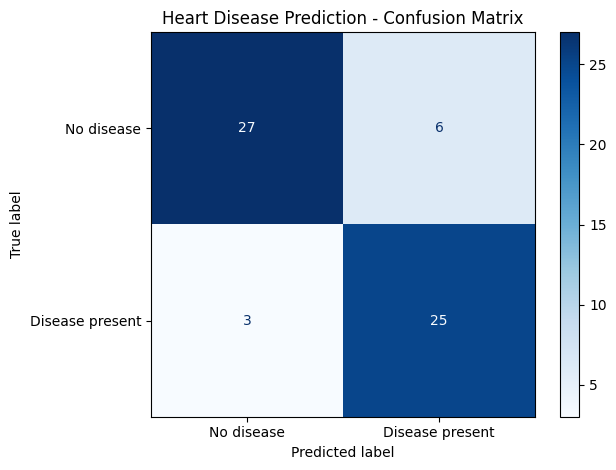

In [22]:
# A confusion matrix compares actual classes with predicted classes.
# labels=[0, 1] fixes the row/column order (no disease, then disease present).
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display the counts in a readable chart.
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease", "Disease present"]
)

# values_format="d" shows whole-number counts; "Blues" is the color palette.
display.plot(cmap="Blues", values_format="d")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 9: Model Persistence

### 9.1 Save the trained model

**Pipeline stage:** Deployment preparation (saving)

**What this cell does:** Saves the trained pipeline, the feature order and a label description into one pickle file, `heart_disease_model.pkl`.

**Why this approach:**
- **Whole pipeline saved:** the scaler and classifier travel together, so the deployed app applies exactly the same scaling as in training.
- **Feature order stored:** each input value must go into the correct column, so the order is saved with the model.
- **Label mapping stored:** lets the app show readable results instead of 0 and 1.
- **A single bundle:** one file is simpler to upload and load in the app.

> Only load pickle files that you created yourself or fully trust, because unpickling can execute code.

In [23]:
# Store the model pipeline and the feature order in one dictionary.
# Feature order matters because each input value must go into the correct column.
model_bundle = {
    "model": heart_model,
    "features": selected_features,
    "target_mapping": {
        0: "No disease indicated",
        1: "Disease present in dataset"
    }
}

# Write the trained object to a file in the current working directory.
# "wb" opens the file for writing in binary mode, as pickle requires.
with open("heart_disease_model.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("Saved model to heart_disease_model.pkl")

Saved model to heart_disease_model.pkl


### 9.2 Reload the model and verify it

**Pipeline stage:** Deployment preparation (verification)

**What this cell does:** Reopens the saved file, extracts the pipeline and feature order, and predicts on the test set again.

**Why this approach:** Reloading and predicting proves the saved file is complete and works on its own. The predictions match the ones made before saving (`[1 1 0 0 0 1 0 0 1 0]`), confirming nothing was lost in the save and load round trip.

In [24]:
# Reopen the saved file in binary read mode.
with open("heart_disease_model.pkl", "rb") as file:
    loaded_bundle = pickle.load(file)

# Extract the saved pipeline and feature order.
loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["features"]

print("Loaded feature order:", loaded_features)

# Confirm that the reloaded model makes predictions.
test_predictions_after_loading = loaded_model.predict(X_test)

# These should match the predictions made before saving.
print(
    "Predictions from reloaded model:",
    test_predictions_after_loading[:10]
)

Loaded feature order: ['age', 'sex', 'cp', 'thalach']
Predictions from reloaded model: [1 1 0 0 0 1 0 0 1 0]


In [25]:
# Download model locally
from google.colab import files

files.download('heart_disease_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary

| Item | Result |
|---|---|
| Dataset | Cleveland Heart Disease, 303 patients |
| Task | Binary classification: disease present or not |
| Inputs | `age`, `sex`, `cp`, `thalach` |
| Preprocessing | Target merged to 0/1, features standardized inside a pipeline |
| Model | `StandardScaler` + `SVC` (RBF kernel, `C=1.0`, `gamma="scale"`, balanced class weights) |
| Test accuracy | 85.25% (61 records) |
| Cross-validation accuracy | about 72% (5 folds, training data) |
| Disease-class recall / precision | 0.89 / 0.81 |
| Saved file | `heart_disease_model.pkl` |

**Key takeaways**
- The pipeline design (split first, scale inside the pipeline) avoids data leakage.
- The gap between test accuracy and cross-validation accuracy shows that the single test split is small and should not be over-interpreted.
- Possible improvements: tune `C` and `gamma` with cross-validated search, compare with other model types, add more informative inputs (such as `thal`, `ca`, `exang` or `oldpeak`, which correlate more strongly with the outcome but contain a few missing values or need clinical tests), and treat `cp` as a nominal category.